# iNatSounds: Fine-Tuning Swin-V2-B with ImageNet-22k Pretrained Weights

**Note:** Most of our training choices come from [Chasmai et al. (2024)](https://arxiv.org/pdf/2506.00343)
, we clearly state when we take a different direction to the paper's process.

**Notebook Goal:** Fine-tuning Swin-V2-B (ImageNet-22k->IN-1k) on iNatSounds following 
the paper's training recipe. Swin-V2-B is a hierarchical transformer with
windowed self-attention, our aim is to improve on the paper's ViT-B-16 baseline.

**Differences when compared to the paper:**
- Backbone: Swin-V2-B IN-22k->IN-1k (paper used ViT-B-16 IN-1k)
- Optimizer: AdamW (paper used Adam for ViT)
- Input size: 256×256 (this Swin-V2 variant requires 256; paper used 224)
- Per-epoch subsample: 25% (paper used 100%), this is done with a fresh random subset 
every epoch (the reason we did this is computational feasibility)
- Batch size 64: again, done for computational feasibility (while the paper had 128)

**What is unchanged compared to the paper:**
- 50 epochs, 5-epoch linear warmup (10%->100% of LR), then cosine decay to 10% of LR
- Weight decay 1e-5
- Mixup in log-exp space (exponentiate dB -> mix -> log back), alpha=1
- Cross-entropy loss, no label smoothing
- Gradient norm clipping at 100
- Sliding-window evaluation: 3-second windows with 1.5-second stride, average softmax


In [ ]:
EPOCHS = 50
EVAL_FREQ = 50 # since evaluating on the validation set is computational expensive we 
# only did it once at the end of training, however, this could be done much more 
# frequently if we have access to more computing power
BATCH_SIZE = 64
LR = 1e-4 # Same as paper for ViT/Adam recipe
TARGET_LENGTH = 512 # c.3 seconds at hop=128 / sr=22050
TEST_STRIDE = 256 # 1.5 seconds at hop=128 / sr=22050 - for sliding-window eval
IMG_SIZE = 256 # Swin-V2-B IN-22k variant requires 256x256
SUBSAMPLE = 0.25
WEIGHT_DECAY = 1e-5 # Paper default
WARMUP_EPOCHS = 5 # Paper default
GRAD_CLIP = 100.0 # Paper default
MIXUP_ALPHA = 1.0 # Paper default with Beta(1, 1) i.e. uniform
print(f"Config: {EPOCHS} epochs (warmup {WARMUP_EPOCHS}), eval every {EVAL_FREQ}, "
      f"batch {BATCH_SIZE}, lr {LR}, wd {WEIGHT_DECAY}")


Config: 50 epochs (warmup 5), eval every 50, batch 64, lr 0.0001, wd 1e-05


In [ ]:
# Downloading Necessary dependencies for the thundercompute instance to work

!pip install torch torchvision torchaudio -q
!pip install timm scikit-learn tqdm matplotlib pandas huggingface_hub safetensors -q


In [ ]:
import os
DATA_DIR = os.path.expanduser("~/data")
SPEC_DIR = os.path.join(DATA_DIR, "spectrograms")
JSON_DIR = DATA_DIR

if os.path.exists(SPEC_DIR):
    print(f"Data already exists at {SPEC_DIR}")
else:
    print(f"Data does not exist and must be imported from Google Drive before proceeding")

for split in ["train", "val", "test"]:
    path = os.path.join(SPEC_DIR, split)
    n = len(os.listdir(path)) if os.path.exists(path) else 0
    print(f"{split}: {n} species folders")


Data already exists at /home/ubuntu/data/spectrograms
train: 5569 species folders
val: 1212 species folders
test: 1212 species folders


In [ ]:
# Importing dependencies
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import json
import os
import copy
import time
import random
import math
from tqdm import tqdm
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader, RandomSampler, default_collate
from sklearn.metrics import average_precision_score, precision_recall_curve
from collections import defaultdict

# Setting seed at zero for reproducibility
SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Checking that we indeed have access to the GPU as it is required for training
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


Device: cuda
GPU: NVIDIA RTX A6000
VRAM: 50.9 GB


## Swin-V2-B Model

We load the model from timm with ImageNet-22k->IN-1k pretrained weights. The 1000-class 
head is replaced with linear layer of "num_classes" parameters (it would be 5,569 
parameters in the case of iNatSounds)


In [6]:
import timm

def build_swin_v2_b(num_classes, pretrained=True):
    """Build Swin-V2-B with ImageNet-22k pretrained weights, head swapped for num_classes."""
    model = timm.create_model(
        'swinv2_base_window12to16_192to256.ms_in22k_ft_in1k',
        pretrained=pretrained,
        num_classes=num_classes,
    )
    return model

print("Swin-V2-B builder defined.")


/home/ubuntu/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Swin-V2-B builder defined.


## Dataset

The spectrograms we import are uint8 arrays of shape (128, T). For training the dataset
returns a single (3, IMG_SIZE, IMG_SIZE) RGB tensor per recording. For evaluation the
dataset returns all sliding 3-second windows (with 1.5-second stride) of each
recording which matches the paper's sliding-window evaluation protocol.

Pipeline per item:
1. Pad or crop time dim:
   - Train: random 3-second crop
   - Eval: produce all sliding windows of length TARGET_LENGTH with stride TEST_STRIDE
2. SpecAugment (freq/time masking) on training only
3. Duplicate to 3 channels i.e. make the image RGB
4. Resize to (3, IMG_SIZE, IMG_SIZE)
5. Normalise with the iNatSounds paper's dataset-level stats (mean=0.6569, std=0.1786) 
as per the iNatSounds repository 

In [ ]:
SPEC_MEAN = 0.6569 # We take this directly from the iNatSounds files (training data mean)
SPEC_STD = 0.1786 # We take this directly from the iNatSounds files (training data stdev)

class InatSoundsDatasetImage(Dataset):
    """iNatSounds dataset returning image-format spectrograms.
    Train mode: returns one random crop with shape (3, IMG_SIZE, IMG_SIZE).
    Eval mode: returns all sliding windows for the recording, with shape (W, 3, IMG_SIZE, IMG_SIZE) with W variable.
    """
    # Two modes because train and eval have different needs: training wants one
    # cheap random crop per sample (so each epoch sees different slices of the
    # same recording), but eval covers the whole recording so we don't
    # miss the moment where the species actually makes a sound.

    def __init__(self, data_root, split_path, sound_aug=False,
                 target_length=512, test_stride=256, img_size=256, mode="test"):
        self.mode = mode
        self.sound_aug = sound_aug # only used in train mode (SpecAugment-style masking)
        self.target_length = target_length # 3s window in spectrogram frames
        self.test_stride = test_stride # 1.5s stride for sliding window at eval time
        self.img_size = img_size

        # Loading the iNatSounds split file (train.json / val.json / test.json).
        with open(split_path, "r") as f:
            dataset = json.load(f)

        # Class lookup from category_id to actual name (in both directions)
        self.class_name2idx = {c["audio_dir_name"]: c["id"] for c in dataset["categories"]}
        self.class_idx2name = {c["id"]: c["audio_dir_name"] for c in dataset["categories"]}
        self.num_classes = len(self.class_name2idx)
        audio_id2path = {au["id"]: au["file_name"] for au in dataset["audio"]}

        # One entry per annotation.
        self.entries = [
            {"path": os.path.join(data_root, audio_id2path[a["audio_id"]].replace(".wav", ".npy")),
             "category_id": a["category_id"],
             "name": audio_id2path[a["audio_id"]].replace(".wav", "")}
            for a in dataset["annotations"]
        ]

        # We create the mask of classes that actually appear in this split. 
        # While training set has 5569 classes the val/test sets have only 1212, 
        # thus, we use this later to the ignore missing classes when we compute all four 
        # metrics: the top-1 accuracy, the top-5 accuracy, the mAP, and mF1.
        classes = sorted(set(self.class_idx2name[e["category_id"]] for e in self.entries))
        self.present_classes_mask = torch.zeros(self.num_classes)
        for c in classes:
            self.present_classes_mask[self.class_name2idx[c]] = 1

        # We normalise geographical coordinates to roughly [-1, 1]. Lat is in [-90, 90]
        # and Lon in [-180, 180] so dividing by (90, 180) gets us into a sensible
        # range. We don't actually use geographical coordinates in this run because they 
        # would require us to use an additional model.
        scale = torch.tensor([90.0, 180.0])
        audio_id2geo = {au["id"]: (au["latitude"], au["longitude"]) for au in dataset["audio"]}
        self.geo = [torch.Tensor(audio_id2geo[a["audio_id"]]) / scale for a in dataset["annotations"]]

    def __len__(self):
        return len(self.entries)

    def _time_selection_train(self, spec):
        """Random crop or pad to target_length. Input/output: (128, T) uint8."""
        t = spec.shape[1]
        # If the recording is shorter than our target window, centre-pad with zeros.
        # This means we split the padding equally on each side of the window (so the actual content approximately centered).
        if t <= self.target_length:
            pad = self.target_length - t
            spec = np.pad(spec, ((0, 0), (pad // 2, pad - pad // 2)), mode='constant')
            return spec
        # Otherwise, we pick a random starting frame so each epoch sees a different slice.
        start = np.random.randint(0, t - self.target_length)
        return spec[:, start:start + self.target_length]

    def _dense_prediction(self, spec):
        """Return all sliding windows of "target_length" with stride "test_stride".
        Input:  (128, T) uint8.
        Output: (W, 128, target_length) uint8 where W is number of windows.
        This mirrors the "dense_prediction" in the paper's reference code.
        """
        time_len = spec.shape[1]
        # We have the same fallback as in train for short recordings, we use padding up 
        # to one full window.
        if time_len <= self.target_length:
            pad = self.target_length - time_len
            spec = np.pad(spec, ((0, 0), (pad // 2, pad - pad // 2)), mode='constant')
            time_len = spec.shape[1]
        # Pad so that an integer number of strided windows fits.
        num = (time_len - self.target_length + self.test_stride - 1) // self.test_stride
        pad = self.test_stride * num - time_len + self.target_length
        spec = np.pad(spec, ((0, 0), (pad // 2, pad - pad // 2)), mode='constant')
        # Slide the window across and stack.
        windows = []
        for i in range(num + 1):
            start = i * self.test_stride
            if start + self.target_length > spec.shape[1]:
                break
            windows.append(spec[:, start:start + self.target_length])
        return np.stack(windows)  # (W, 128, target_length)

    # SpecAugment-style frequency masking: we zero out a random horizontal stripe of
    # the spectrogram, this is also directly from the paper's training recipe. The aim 
    # is that it forces the model to not rely on any single frequency band.
    def _fmask(self, spec, max_len=15):
        if spec.shape[0] <= max_len:
            return spec  # spectrogram is too thin to mask, skip
        f0 = np.random.randint(0, spec.shape[0] - max_len)
        w = np.random.randint(0, max_len)
        spec[f0:f0 + w, :] = 0
        return spec

    # We reproduce the same augmentation but vertically (this is in the time dimension).
    def _tmask(self, spec, max_len=50):
        if spec.shape[1] <= max_len:
            return spec
        t0 = np.random.randint(0, spec.shape[1] - max_len)
        w = np.random.randint(0, max_len)
        spec[:, t0:t0 + w] = 0
        return spec

    def _to_image_tensor(self, spec_2d_or_3d):
        """Apply: /255 -> 3-channel -> resize -> normalise.

        Input shape is either (128, T) or (W, 128, T).
        Output: (3, IMG, IMG) or (W, 3, IMG, IMG).
        """
        # Spectrograms are stored as uint8 to save disk space. We convert to float
        # and rescale to [0, 1] so they look like a normal image to the network.
        x = torch.from_numpy(spec_2d_or_3d.astype(np.float32) / 255.0)
        if x.dim() == 2:
            # Single window case (training).
            # (128, T) -> (3, 128, T): the pretrained Swin expects 3-channel RGB
            # input, so we triple the single spectrogram channel three times.
            x = x.unsqueeze(0).repeat(3, 1, 1)
            # Bilinear resize to the model's expected input size (256 for this Swin variant).
            x = F.interpolate(x.unsqueeze(0), size=(self.img_size, self.img_size),
                              mode='bilinear', align_corners=False).squeeze(0)
        else:
            # Batched windows case (eval): same idea but with an extra leading dimension.
            # (W, 128, T) -> (W, 3, 128, T)
            x = x.unsqueeze(1).repeat(1, 3, 1, 1)
            x = F.interpolate(x, size=(self.img_size, self.img_size),
                              mode='bilinear', align_corners=False)
        # Final z-score normalisation using the precomputed dataset mean/std.
        return (x - SPEC_MEAN) / SPEC_STD

    def __getitem__(self, idx):
        e = self.entries[idx]
        spec = np.load(e["path"]) # (128, T) uint8
        label = self.class_name2idx[self.class_idx2name[e["category_id"]]]

        if self.mode == "train":
            # One random crop, SpecAugment (if selected), then to image tensor.
            spec = self._time_selection_train(spec)
            if self.sound_aug:
                spec = self._fmask(spec)
                spec = self._tmask(spec)
            img = self._to_image_tensor(spec)  # (3, IMG, IMG)
            return img, label, self.geo[idx], e["name"]
        else:
            # Eval mode: return every sliding window. The downstream collate function 
            # (eval_collate) will flatten these into one big batch and we average 
            # softmax across windows per recording at metric time.
            windows = self._dense_prediction(spec)  # (W, 128, target_length)
            imgs = self._to_image_tensor(windows)   # (W, 3, IMG, IMG)
            num_windows = imgs.shape[0]
            # Repeat label/geo/name to match per-window structure (collated downstream).
            labels = torch.tensor([label] * num_windows, dtype=torch.long)
            return imgs, labels, self.geo[idx], e["name"]

In [ ]:
def mixup_collate_train(batch):
    """We apply the same mixup in the dB-power space as the paper, in the collate function.
    The paper mixes spectrograms in the power domain (exp(dB) -> linear average ->
    log back), as mentioned in the appendix of our paper, this is the physically correct 
    operation since dB is a logarithmic scale. Linear interpolation of dB values would 
    correspond to a geometric mean of powers, not an arithmetic mean.
    Our pipeline z-score normalises spectrograms via (x - SPEC_MEAN) / SPEC_STD
    after rescaling raw dB to [0, 1] and dividing by 255. To do mixup correctly we
    must invert these transforms back to a dB-like scale, perform exp -> mix -> log,
    then re-apply normalisation.
    """
    images, labels, geo, names = default_collate(batch)
    # Step 1+2: invert normalisation and map to dB-like scale
    unnorm = images * SPEC_STD + SPEC_MEAN
    db_approx = unnorm * 12.0 - 10.0
    # Step 3: paper-style mixup in power domain
    power = torch.exp(db_approx - 10.0) # subtract 10 to avoid exp overflow
    lam = float(np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA))
    perm = torch.randperm(images.size(0))
    power_mix = lam * power + (1.0 - lam) * power[perm]
    db_mix = torch.log(power_mix + 1e-30) + 10.0 # +eps for numerical safety
    # Step 4+5: reverse mapping and re-normalise
    unnorm_mix = (db_mix + 10.0) / 12.0
    images_mix = (unnorm_mix - SPEC_MEAN) / SPEC_STD
    # Soft one-hot labels
    num_classes = NUM_CLASSES_FOR_COLLATE
    labels_oh = F.one_hot(labels, num_classes=num_classes).float()
    labels_mix = lam * labels_oh + (1.0 - lam) * labels_oh[perm]
    return images_mix, labels_mix, geo, names


def eval_collate(batch):
    """Stack per-recording sliding windows into one big batch tensor and remember
    which windows belong to which recording (for averaging at metric time).
    """
    imgs_list   = [b[0] for b in batch] # list of (W_i, 3, IMG, IMG)
    labels_list = [b[1] for b in batch] # list of (W_i,)
    geo_list    = [b[2] for b in batch]
    names_list  = [b[3] for b in batch]

    images = torch.cat(imgs_list,   dim=0) # (Sum of W_i, 3, IMG, IMG)
    labels = torch.cat(labels_list, dim=0) # (Sum of W_i,)
    expanded_names = []
    expanded_geo   = []
    for n, g, im in zip(names_list, geo_list, imgs_list):
        expanded_names.extend([n] * im.shape[0])
        expanded_geo.extend([g] * im.shape[0])
    geo = torch.stack(expanded_geo, dim=0)
    return images, labels, geo, expanded_names


def build_dataloaders_image(spectrogram_dir, json_dir, batch_size=128, sound_aug=True):
    train_data = InatSoundsDatasetImage(
        spectrogram_dir, os.path.join(json_dir, "train.json"),
        sound_aug=sound_aug, mode="train",
        target_length=TARGET_LENGTH, test_stride=TEST_STRIDE, img_size=IMG_SIZE)
    val_data = InatSoundsDatasetImage(
        spectrogram_dir, os.path.join(json_dir, "val.json"),
        mode="test", target_length=TARGET_LENGTH, test_stride=TEST_STRIDE, img_size=IMG_SIZE)
    test_data = InatSoundsDatasetImage(
        spectrogram_dir, os.path.join(json_dir, "test.json"),
        mode="test", target_length=TARGET_LENGTH, test_stride=TEST_STRIDE, img_size=IMG_SIZE)

    num_classes = train_data.num_classes
    global NUM_CLASSES_FOR_COLLATE
    NUM_CLASSES_FOR_COLLATE = num_classes # used inside mixup_collate_train

    # Train loader: 25% subsample, resampled fresh every epoch via RandomSampler.
    n_sub = int(len(train_data) * SUBSAMPLE)
    sampler = RandomSampler(train_data, replacement=False, num_samples=n_sub)
    train_loader = DataLoader(train_data, batch_size=batch_size, sampler=sampler,
                              num_workers=4, pin_memory=True, drop_last=True,
                              collate_fn=mixup_collate_train)

    # Eval loaders: small batch_size of recordings (each yields several windows).
    val_loader = DataLoader(val_data, batch_size=8, shuffle=False, num_workers=2, 
                            pin_memory=True, collate_fn=eval_collate)
    test_loader = DataLoader(test_data, batch_size=8, shuffle=False, num_workers=2, 
                             pin_memory=True, collate_fn=eval_collate)

    for l in [train_loader, val_loader, test_loader]:
        l.num_classes = num_classes
    train_loader.present_classes_mask = train_data.present_classes_mask
    val_loader.present_classes_mask = val_data.present_classes_mask
    test_loader.present_classes_mask = test_data.present_classes_mask
    return train_loader, val_loader, test_loader, num_classes


# Placeholder so the collate function can reference num_classes. Will be set by builder.
NUM_CLASSES_FOR_COLLATE = 5569

train_loader, val_loader, test_loader, num_classes = build_dataloaders_image(
    SPEC_DIR, JSON_DIR, batch_size=BATCH_SIZE, sound_aug=True)

print(f"Classes: {num_classes}")
print(f"Train: full size {len(train_loader.dataset)}, "
      f"per-epoch subset {int(len(train_loader.dataset)*SUBSAMPLE)} "
      f"({len(train_loader)} batches @ bs={BATCH_SIZE})")
print(f"Val recordings: {len(val_loader.dataset)} (recording batch_size=8)")
print(f"Test recordings: {len(test_loader.dataset)} (recording batch_size=8)")


Classes: 5569
Train: full size 137012, per-epoch subset 34253 (535 batches @ bs=64)
Val recordings: 45698 (recording batch_size=8)
Test recordings: 49527 (recording batch_size=8)


## Sanity Check

We conduct a quick sanity check with dimensions before training. 

In [ ]:
model = build_swin_v2_b(num_classes).to(device)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"\nSwin-V2-B (IN-22k->IN-1k pretrained) | {n_params:.1f}M params | {num_classes} classes")

with torch.no_grad():
    test_batch = next(iter(train_loader))
    test_input = test_batch[0][:2].to(device)
    test_labels_soft = test_batch[1][:2].to(device)  # (2, num_classes) soft labels (mixup)
    test_out = model(test_input)
    # Cross-entropy against soft labels:
    test_loss = -(test_labels_soft * F.log_softmax(test_out, dim=-1)).sum(dim=-1).mean()
    print(f"Train batch input: {test_input.shape} -> Output: {test_out.shape}")
    print(f"Train soft-label loss (expect c.{np.log(num_classes):.1f}): {test_loss.item():.2f}")

# Eval-mode sanity check (sliding windows)
val_batch = next(iter(val_loader))
print(f"\nVal batch (8 recordings collated): images={val_batch[0].shape}, "
      f"labels={val_batch[1].shape}, names={len(val_batch[3])}")
del model
torch.cuda.empty_cache()


Swin-V2-B (IN-22k->IN-1k pretrained) | 92.6M params | 5569 classes


Train batch input: torch.Size([2, 3, 256, 256]) -> Output: torch.Size([2, 5569])
Train soft-label loss (expect c.8.6): 8.92


Val batch (8 recordings collated): images=torch.Size([102, 3, 256, 256]), labels=torch.Size([102]), names=102
Sanity check passed!


## Metrics & Training Loop


In [ ]:
class SlidingWindowMetrics:
    def __init__(self, num_classes, present_classes_mask):
        self.num_classes = num_classes
        self.present_idx = torch.where(present_classes_mask > 0)[0]
        self.softmax = nn.Softmax(dim=-1)
        self.t1 = defaultdict(int)
        self.t5 = defaultdict(int)
        self.n  = defaultdict(int)
        # Use incremental aggregation: store sum + count per recording
        self._buf_sum = {}
        self._buf_count = {}
        self._buf_label = {}
    
    def update(self, names, logits, labels):
        probs = self.softmax(logits)
        for i, name in enumerate(names):
            if name not in self._buf_sum:
                self._buf_sum[name] = probs[i].clone()
                self._buf_count[name] = 1
                self._buf_label[name] = labels[i].item()
            else:
                self._buf_sum[name] += probs[i]
                self._buf_count[name] += 1
    
    def compute(self):
        # Build dense numpy arrays directly because a Python list was too 
        # computationally expensive in this case
        names = list(self._buf_sum.keys())
        N = len(names)
        K = len(self.present_idx)
        present_idx_np = self.present_idx.numpy()
        
        preds_array = np.zeros((N, K), dtype=np.float32)
        gts_array = np.zeros((N, K), dtype=np.int8)  # int8 instead of float64 list
        
        for i, name in enumerate(names):
            avg_probs = (self._buf_sum[name] / self._buf_count[name]).numpy()
            preds_array[i] = avg_probs[present_idx_np]
            gt = self._buf_label[name]
            # Find which present-class index corresponds to gt
            gt_present_pos = np.where(present_idx_np == gt)[0]
            if len(gt_present_pos) > 0:
                gts_array[i, gt_present_pos[0]] = 1
            
            # Top-1/Top-5 (compute on full probability vector, not just present)
            full_probs = self._buf_sum[name] / self._buf_count[name]
            self.t1[gt] += int(full_probs.argmax().item() == gt)
            self.t5[gt] += int(gt in torch.topk(full_probs, 5).indices.tolist())
            self.n[gt] += 1
        
        t1 = np.mean([self.t1[c]/self.n[c] for c in self.n if self.n[c] > 0])
        t5 = np.mean([self.t5[c]/self.n[c] for c in self.n if self.n[c] > 0])
        ap = average_precision_score(gts_array, preds_array, average=None)
        # vectorised best-F1 per class:
        def best_f1_per_class(gts, preds):
            f1s = []
            for c in range(gts.shape[1]):
                pr, re, _ = precision_recall_curve(gts[:, c], preds[:, c])
                f1s.append((2 * pr * re / (pr + re + 1e-10)).max())
            return np.array(f1s)
        f1s = best_f1_per_class(gts_array, preds_array)
        return {"top1": 100*t1, "top5": 100*t5,
                "mAP": 100*np.mean(ap), "mF1": 100*np.mean(f1s)}

In [ ]:
def train_one_epoch(model, loader, optimizer, scaler):
    """Single training epoch. Mixup is applied in the collate function, so each batch
    already has mixed images and soft labels of shape (B, num_classes)."""
    model.train()
    tot_loss, tot_acc, nb = 0.0, 0.0, 0
    pbar = tqdm(loader, desc="Training", leave=False)
    for batch in pbar:
        specs = batch[0].to(device, non_blocking=True)
        soft_labels = batch[1].to(device, non_blocking=True)  # (B, num_classes)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            logits = model(specs)
            # Soft-label cross entropy. Equivalent to plain CE when labels are one-hot.
            loss = -(soft_labels * F.log_softmax(logits, dim=-1)).sum(dim=-1).mean()
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(optimizer)
        scaler.update()

        # Accuracy: prediction vs argmax of soft label
        preds = logits.argmax(dim=-1)
        targets = soft_labels.argmax(dim=-1)
        acc = (preds == targets).float().mean()

        tot_loss += loss.item(); tot_acc += acc.item(); nb += 1
        pbar.set_postfix(loss=f"{loss.item():.3f}", acc=f"{acc.item():.3f}")
    return tot_loss/nb, tot_acc/nb


@torch.no_grad()
def evaluate(model, loader, num_classes, mask, sub_batch_size=64):
    """Sliding-window evaluation. Each recording yields W windows; we forward all of
    them, then aggregate by averaging softmax across windows per recording.
    The collate function returns per-batch tensors of shape (Sum of W_i, 3, IMG, IMG)
    where Sum of W_i can be large for a 'recording-batch' of 8 samples. We further chunk
    those into sub-batches of "sub_batch_size" to keep VRAM bounded (we had issues
    when running this otherwise i.e. our run would crash)
    """
    model.eval()
    metrics = SlidingWindowMetrics(num_classes, mask)
    mask_dev = mask.to(device)

    for batch in tqdm(loader, desc="Eval", leave=False):
        specs, labels, _geo, names = batch
        specs = specs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Run forward in sub-batches to control VRAM
        all_logits = []
        for s in range(0, specs.size(0), sub_batch_size):
            with torch.amp.autocast('cuda'):
                out = model(specs[s:s+sub_batch_size])
            all_logits.append(out.float())
        logits = torch.cat(all_logits, dim=0)

        # Mask-out species absent from the eval split (we do this by setting their 
        # logit to -inf so they cannot be argmax-predicted and contribute zero softmax 
        # probability).
        logits = logits.masked_fill(mask_dev.unsqueeze(0) == 0, float('-inf'))
        metrics.update(names, logits.cpu(), labels.cpu())

    return metrics.compute()


In [ ]:
def train_swin_experiment(num_classes, train_loader, val_loader, test_loader,
                          epochs=50, eval_freq=5, lr=1e-4, save_dir="./checkpoints"):
    os.makedirs(save_dir, exist_ok=True)
    print(f"\n{'='*60}")
    print(f"Training: Swin-V2-B (IN-22k->IN-1k pretrained) | {epochs} epochs")
    print(f"{'='*60}")

    model = build_swin_v2_b(num_classes).to(device)
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"Params: {n_params:.1f}M")

    # Single optimizer parameter group, same weight decay as Chasmai et al. (2024)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=WEIGHT_DECAY,
    )
    print(f"Optimizer: AdamW | lr={lr:.0e} | wd={WEIGHT_DECAY}")

    # Same scheduler as the paper:
    # 5-epoch linear warmup from 10% -> 100% of LR, then cosine decay over remaining
    # (epochs - 5) epochs from 100% -> 10% of LR.
    s1 = torch.optim.lr_scheduler.LinearLR(optimizer, 
                                           start_factor=0.1, 
                                           total_iters=WARMUP_EPOCHS)
    s2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, 
                                                    T_max=epochs - WARMUP_EPOCHS,
                                                    eta_min=lr * 0.1)
    sched = torch.optim.lr_scheduler.SequentialLR(optimizer, [s1, s2],
                                                  milestones=[WARMUP_EPOCHS])
    print(f"Scheduler: LinearLR warmup ({WARMUP_EPOCHS} epochs) -> CosineAnnealingLR")

    scaler = torch.amp.GradScaler('cuda')

    hist = {"train_loss":[], "train_acc":[], "val_top1":[], "val_top5":[],
        "val_mAP":[], "val_mF1":[], "lr":[], "val_eval_epochs":[]}
    best_mAP, best_w, best_ep = -1.0, None, -1
    t0 = time.time()

    for ep in range(epochs):
        cur_lr = sched.get_last_lr()[-1]
        loss, acc = train_one_epoch(model, train_loader, optimizer, scaler)
        elapsed = (time.time() - t0) / 60
        hist["train_loss"].append(loss); hist["train_acc"].append(acc); hist["lr"].append(cur_lr)
        print(f"Ep {ep+1:2d}/{epochs} | LR {cur_lr:.1e} | Loss {loss:.4f} | "
              f"Acc {100*acc:.1f}% | {elapsed:.0f}min")

        if (ep + 1) % 10 == 0 or ep == epochs - 1:
            rolling_path = os.path.join(save_dir, f"swin_v2_b_epoch{ep+1:03d}.pt")
            torch.save(model.state_dict(), rolling_path)
            print(f"  [checkpoint] saved {rolling_path}")
        
        if (ep + 1) % eval_freq == 0 or ep == epochs - 1:
            vr = evaluate(model, val_loader, num_classes, val_loader.present_classes_mask)
            hist["val_top1"].append(vr["top1"])
            hist["val_top5"].append(vr["top5"])
            hist["val_mAP"].append(vr["mAP"])
            hist["val_mF1"].append(vr["mF1"])
            hist["val_eval_epochs"].append(ep + 1)
            print(f"  VAL | Top1:{vr['top1']:.1f}% Top5:{vr['top5']:.1f}% "
                  f"mAP:{vr['mAP']:.1f}% mF1:{vr['mF1']:.1f}%")
            if vr["mAP"] > best_mAP:
                best_mAP = vr["mAP"]; best_ep = ep + 1
                best_w = copy.deepcopy(model.state_dict())
                torch.save(best_w, os.path.join(save_dir, "swin_v2_b_best.pt"))
                print(f"  >> New best mAP={best_mAP:.1f}% (epoch {best_ep})")
            import gc; gc.collect()

        sched.step()

    print(f"\nDone in {(time.time()-t0)/60:.0f}min. Best epoch: {best_ep}")
    if best_w is not None:
        model.load_state_dict(best_w)
        
    # Free training-time state before the test eval
    del optimizer, scaler, sched, s1, s2
    import gc; gc.collect(); torch.cuda.empty_cache()

    tr = evaluate(model, test_loader, num_classes, test_loader.present_classes_mask)
    
    print(f"\n>>> TEST (Swin-V2-B) | Top1:{tr['top1']:.1f}% Top5:{tr['top5']:.1f}% "
          f"mAP:{tr['mAP']:.1f}% mF1:{tr['mF1']:.1f}%")
    tr["best_epoch"] = best_ep
    tr["time_min"] = (time.time() - t0) / 60
    return model, hist, tr


## Run Experiment


In [14]:
model, history, results = train_swin_experiment(
    num_classes, train_loader, val_loader, test_loader,
    epochs=EPOCHS, eval_freq=EVAL_FREQ, lr=LR)
print("\nEXPERIMENT COMPLETE")


Training: Swin-V2-B (IN-22k->IN-1k pretrained) | 50 epochs


Params: 92.6M
Optimizer: AdamW | lr=1e-04 | wd=1e-05
Scheduler: LinearLR warmup (5 epochs) -> CosineAnnealingLR


Training:   0%|          | 0/535 [00:08<?, ?it/s, acc=0.000, loss=8.838]

Training:   0%|          | 1/535 [00:08<1:13:22,  8.25s/it, acc=0.000, loss=8.838]

Training:   0%|          | 1/535 [00:09<1:13:22,  8.25s/it, acc=0.000, loss=8.721]

Training:   0%|          | 2/535 [00:09<34:24,  3.87s/it, acc=0.000, loss=8.721]  

... (53,766 outputs left out)

Eval: 100%|█████████▉| 6189/6191 [55:54<00:01,  1.44it/s]


Eval: 100%|█████████▉| 6190/6191 [55:55<00:00,  1.42it/s]


Eval: 100%|██████████| 6191/6191 [55:55<00:00,  1.55it/s]


>>> TEST (Swin-V2-B) | Top1:60.9% Top5:81.4% mAP:70.3% mF1:71.5%
EXPERIMENT COMPLETE


In [15]:
# Save data
import json as jl
with open("swin_v2_b_history.json", "w") as f:
    jl.dump({"history": history, "results": results}, f, default=float, indent=2)
print("History + results saved to swin_v2_b_history.json")

History + results saved to swin_v2_b_history.json


## Results Comparison


In [16]:
import pandas as pd

comparison = {
    "MobileNet-V3 (paper)":           {"top1": 49.1, "top5": 69.5, "mAP": 60.0, "mF1": 63.2},
    "ResNet-50 (paper)":              {"top1": 52.6, "top5": 74.3, "mAP": 62.8, "mF1": 65.5},
    "ViT-B-16 (paper)":               {"top1": 53.6, "top5": 74.3, "mAP": 64.4, "mF1": 66.9},
    "Swin-V2-B IN-22k (ours)":        {k: results[k] for k in ["top1","top5","mAP","mF1"]},
}
df = pd.DataFrame(comparison).T
df.columns = ["Top-1 (%)", "Top-5 (%)", "mAP (%)", "mF1 (%)"]
print("="*70)
print("RESULTS: iNatSounds Test Set (50 epochs, masked, no geo-prior)")
print("="*70)
print(df.to_string(float_format=lambda x: f"{x:.1f}"))

RESULTS: iNatSounds Test Set (50 epochs, masked, no geo-prior)
                         Top-1 (%)  Top-5 (%)  mAP (%)  mF1 (%)
MobileNet-V3 (paper)          49.1       69.5     60.0     63.2
ResNet-50 (paper)             52.6       74.3     62.8     65.5
ViT-B-16 (paper)              53.6       74.3     64.4     66.9
Swin-V2-B IN-22k (ours)       60.9       81.4     70.3     71.5


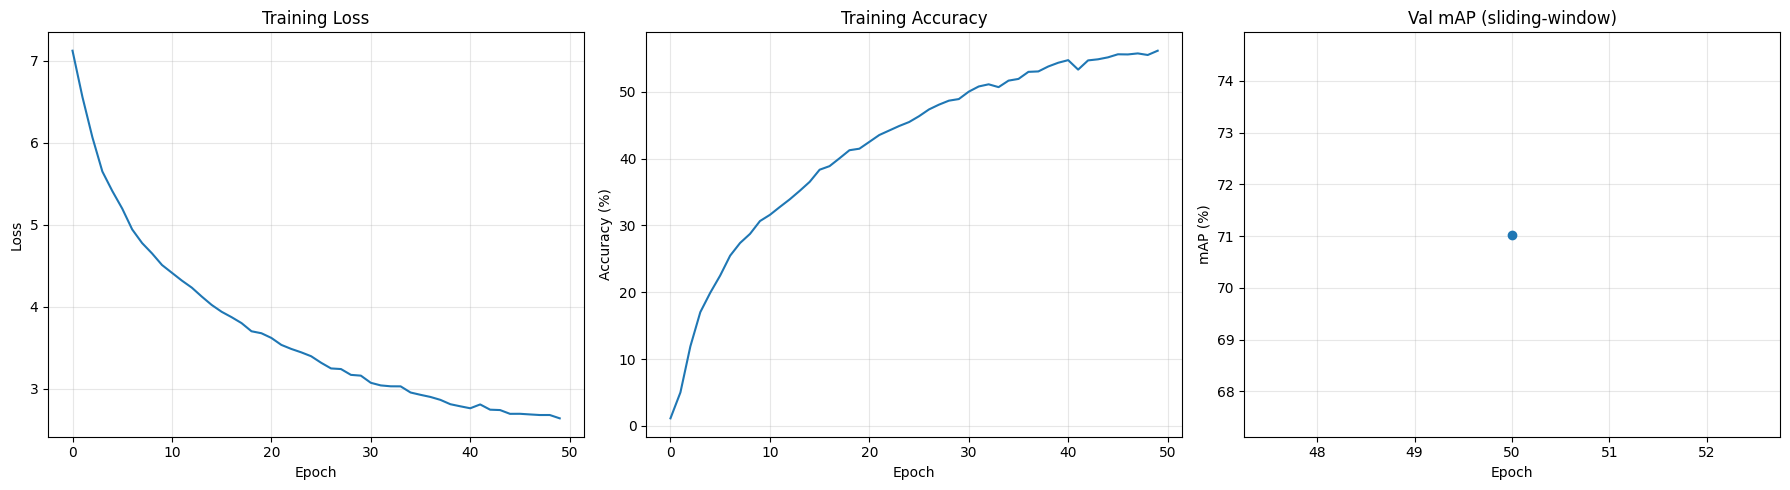

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(history["train_loss"]); axes[0].set(xlabel="Epoch", ylabel="Loss", title="Training Loss"); axes[0].grid(alpha=0.3)
axes[1].plot([a*100 for a in history["train_acc"]]); axes[1].set(xlabel="Epoch", ylabel="Accuracy (%)", title="Training Accuracy"); axes[1].grid(alpha=0.3)
if history["val_mAP"]:
    axes[2].plot(history["val_eval_epochs"], history["val_mAP"], 'o-')
axes[2].set(xlabel="Epoch", ylabel="mAP (%)", title="Val mAP (sliding-window)"); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.savefig("swin_v2_b_curves.png", dpi=150); plt.show()


In [18]:
import json as jl
import numpy as np
with open("swin_v2_b_results.json", "w") as f:
    jl.dump({
        "config": {"epochs": EPOCHS, "warmup_epochs": WARMUP_EPOCHS,
                   "batch_size": BATCH_SIZE, "lr": LR, "weight_decay": WEIGHT_DECAY,
                   "img_size": IMG_SIZE, "target_length": TARGET_LENGTH,
                   "test_stride": TEST_STRIDE, "subsample": SUBSAMPLE,
                   "grad_clip": GRAD_CLIP, "mixup_alpha": MIXUP_ALPHA,
                   "model": "timm swinv2_base_window12to16_192to256.ms_in22k_ft_in1k"},
        "results": {k: float(v) if isinstance(v, (int, float, np.floating)) else v
                    for k, v in results.items()}
    }, f, indent=2)
print("Saved to swin_v2_b_results.json")


Saved to swin_v2_b_results.json
